# Tier 1: Black Scholes

A walks through the closed form price, the two ideas it rests on
(continuous compounding and the normal CDF as an area), the Greeks, and implied volatility by
Newton's method, all with the `ope` library.

The condensed theory is in [NOTES.md](../docs/NOTES.md) and the design choices in
[DECISIONS.md](../docs/DECISIONS.md). The number below is recomputed when the notebook runs, and CI
runs it top to bottom on every push

Units: `r`, `q` and `sigma` are annualized and continuously compounded, `T` is in years.

In [1]:
import itertools
import math

import matplotlib.pyplot as plt
import numpy as np

from ope import call_price, d1_d2, greeks, implied_vol_result, price, put_price
from ope.black_scholes import norm_cdf, norm_pdf
from ope.plots import plot_greeks_vs_spot

## 1. Hull's example

$S = 42$, $K = 40$, $T = 0.5$, $r = 10\%$, $\sigma = 20\%$, no dividends. The call is:

$$C = S\,N(d_1) - K e^{-rT} N(d_2), \qquad d_1 = \frac{\ln(S/K) + (r + \sigma^2/2)T}{\sigma\sqrt{T}}, \quad d_2 = d_1 - \sigma\sqrt{T}$$

Read it as a replicating portfolio: hold $N(d_1)$ shares and borrow $K e^{-rT} N(d_2)$ in cash.
$N(d_2)$ is the risk neutral probability that the call ends in the money.

In [2]:
S, K, T, r, sigma = 42.0, 40.0, 0.5, 0.10, 0.20
d1, d2 = d1_d2(S, K, T, r, sigma)
n_d1, n_d2 = float(norm_cdf(d1)), float(norm_cdf(d2))
stock_leg = S * n_d1
cash_leg = K * math.exp(-r * T) * n_d2

print(f"d1 = {d1:.4f}   d2 = {d2:.4f}")
print(f"N(d1) = {n_d1:.4f}   shares held to replicate the call")
print(f"N(d2) = {n_d2:.4f}   risk neutral probability of ending in the money")
print(f"call  = {stock_leg:.4f} - {cash_leg:.4f} = {stock_leg - cash_leg:.4f}")
print(f"ope:  call {call_price(S, K, T, r, sigma):.4f}, put {put_price(S, K, T, r, sigma):.4f}")

d1 = 0.7693   d2 = 0.6278
N(d1) = 0.7791   shares held to replicate the call
N(d2) = 0.7349   risk neutral probability of ending in the money
call  = 32.7235 - 27.9641 = 4.7594
ope:  call 4.7594, put 0.8086


## 2. Continuous compounding

The engine discounts with $e^{-rT}$. That is the limit of $(1 + r/n)^{-nT}$ when interest is
paid $n$ times a year and $n$ grows. With $r = 10\%$ over half a year, the disparity between annual
and continuous compounding is already in the 3rd decimal which is not negligible.

In [3]:
for n in (1, 2, 4, 12, 365, 10_000):
    print(f"n = {n:>6}   (1 + r/n)^(-nT) = {(1 + r / n) ** (-n * T):.6f}")
print(f"continuous     e^(-rT)       = {math.exp(-r * T):.6f}")

n =      1   (1 + r/n)^(-nT) = 0.953463
n =      2   (1 + r/n)^(-nT) = 0.952381
n =      4   (1 + r/n)^(-nT) = 0.951814
n =     12   (1 + r/n)^(-nT) = 0.951427
n =    365   (1 + r/n)^(-nT) = 0.951236
n =  10000   (1 + r/n)^(-nT) = 0.951230
continuous     e^(-rT)       = 0.951229


## 3. $N(x)$

$N(x)$ is the area under the bell curve to the left of $x$. So $N(0) = 0.5$ (half the area),
and the probability of one exact point is 0: a single point has no area. The shaded area below
is $N(d_2)$ for Hull's example.

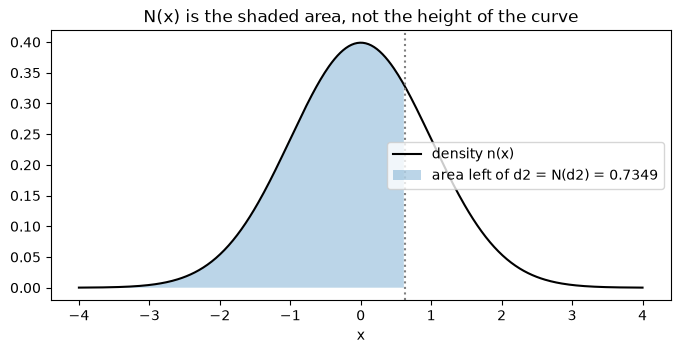

In [4]:
x = np.linspace(-4, 4, 400)
left = x <= d2
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(x, norm_pdf(x), color="black", label="density n(x)")
ax.fill_between(
    x[left], norm_pdf(x[left]), alpha=0.3, label=f"area left of d2 = N(d2) = {n_d2:.4f}"
)
ax.axvline(d2, color="gray", linestyle=":")
ax.set_xlabel("x")
ax.set_title("N(x) is the shaded area, not the height of the curve")
ax.legend()
plt.show()

## 4. Price vs. spot, as expiry gets close

With less time left, the price curve sits closer to the payoff $\max(S - K, 0)$. At $T = 0$ it is
the payoff. The difference between the curve and the payoff is the time value, largest at the
money.

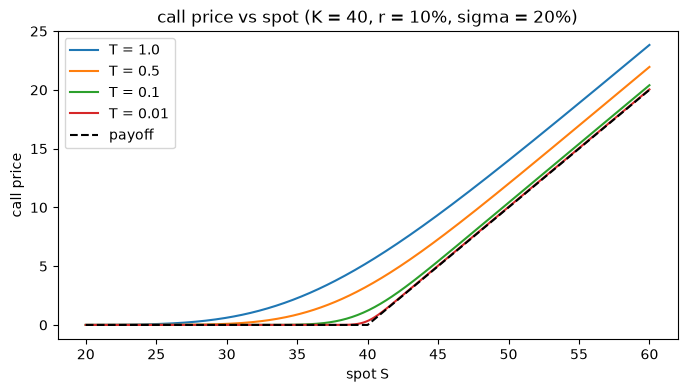

In [5]:
spots = np.linspace(20, 60, 401)
fig, ax = plt.subplots(figsize=(8, 4))
for t in (1.0, 0.5, 0.1, 0.01):
    ax.plot(spots, call_price(spots, K, t, r, sigma), label=f"T = {t}")
ax.plot(spots, np.maximum(spots - K, 0), color="black", linestyle="--", label="payoff")
ax.set_xlabel("spot S")
ax.set_ylabel("call price")
ax.set_title("call price vs spot (K = 40, r = 10%, sigma = 20%)")
ax.legend()
plt.show()

## 5. Price vs. volatility

The price rises with $\sigma$, from the no-arbitrage lower bound $\max(S - Ke^{-rT}, 0)$ to the
upper bound $S$. It increases strictly in between: each price inside the bounds matches one
volatility, which makes implied volatility well defined.

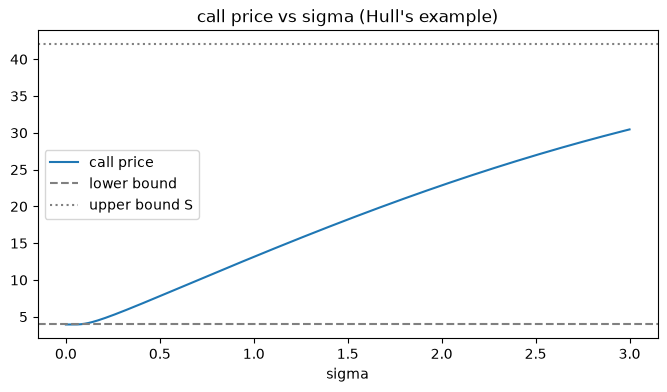

In [ ]:
vols = np.linspace(0.0, 3.0, 301)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(vols, call_price(S, K, T, r, vols), label="call price")
ax.axhline(max(S - K * math.exp(-r * T), 0.0), color="gray", linestyle="--", label="lower bound")
ax.axhline(S, color="gray", linestyle=":", label="upper bound S")
ax.set_xlabel("sigma")
ax.set_title("call price vs sigma (hull's example)")
ax.legend()
plt.show()

## 6. The Greeks

Each Greek is a partial derivative: move one input, hold the others fixed. In the charts:

- **Delta** runs from 0 to 1 for the call and from -1 to 0 for the put. Call delta minus put
  delta is always 1 (without dividends).
- **Gamma and vega** are the same curve for calls and puts, because put-call parity is linear in
  $S$ and has no $\sigma$.
- **Theta** is most negative near the money. A deep ITM put has a positive theta: its value is
  close to $Ke^{-rT}$, which grows as time passes.
- Units are Hull's: vega and rho per 1.00, theta per year.

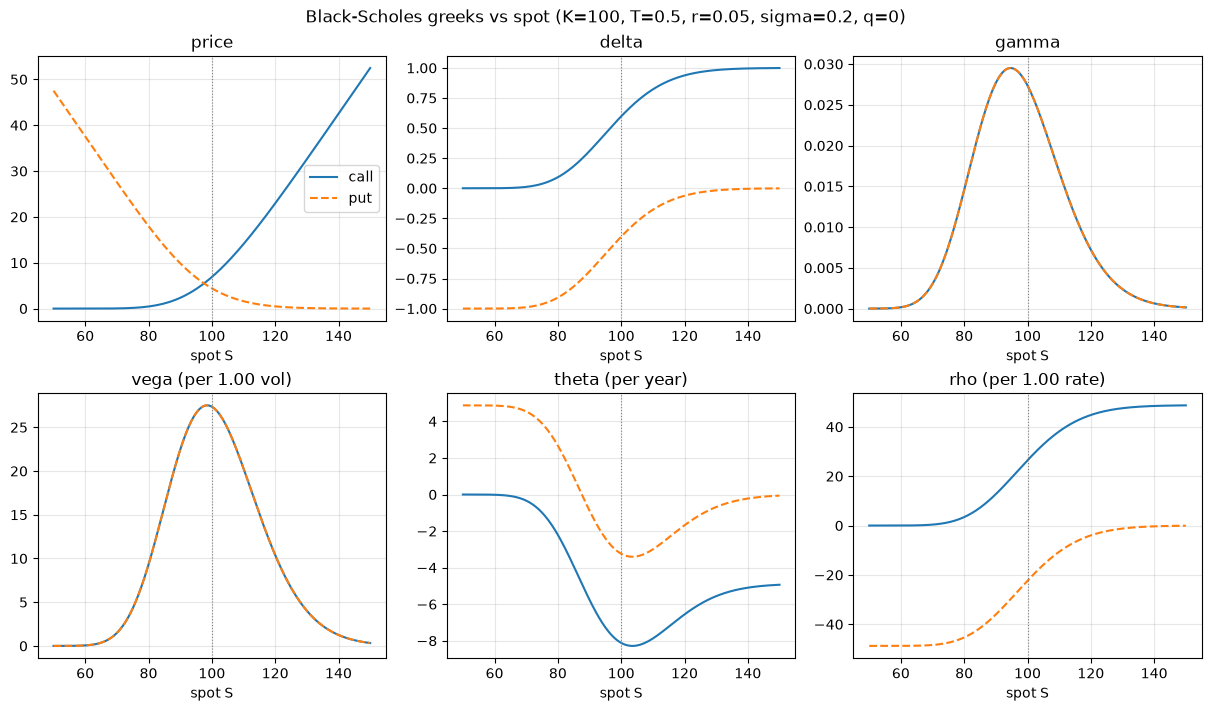

In [7]:
plot_greeks_vs_spot(K=100, T=0.5, r=0.05, sigma=0.2)

## 7. Gamma near expiry

At the money, gamma is about $n(0)/(S\sigma\sqrt{T})$, so it grows like $1/\sqrt{T}$ as expiry
gets close. A short-dated ATM option has a delta that swings from 0 to 1 over a tiny move in
spot, which makes it hard to hedge.

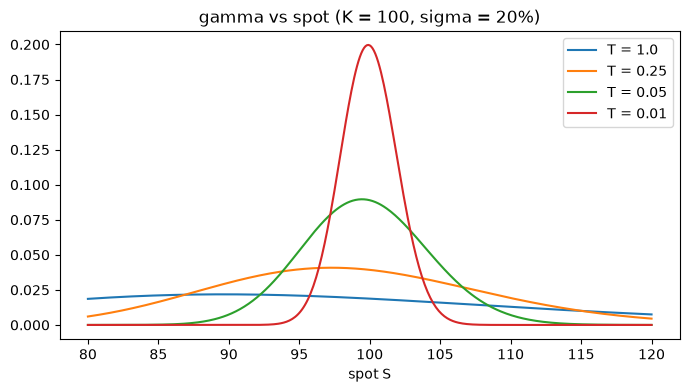

In [8]:
spots = np.linspace(80, 120, 401)
fig, ax = plt.subplots(figsize=(8, 4))
for t in (1.0, 0.25, 0.05, 0.01):
    ax.plot(spots, greeks("call", spots, 100, t, 0.05, 0.2).gamma, label=f"T = {t}")
ax.set_xlabel("spot S")
ax.set_title("gamma vs spot (K = 100, sigma = 20%)")
ax.legend()
plt.show()

## 8. Checking the Greeks by bumping inputs

A Greek can be checked without its formula: bump one input up and down and take the slope
(a central difference). Hull's Greeks example is $S = 49$, $K = 50$, $T = 20/52$, $r = 5\%$,
$\sigma = 20\%$. The test suite runs the same check on 200 random sets.

In [9]:
p = {"S": 49.0, "K": 50.0, "T": 20 / 52, "r": 0.05, "sigma": 0.2}
g = greeks("call", **p)


def v(**bump: float) -> float:
    return float(price("call", **(p | bump)))


hS, hs, hT, hr = 1e-4 * p["S"], 1e-4 * p["sigma"], 1e-4 * p["T"], 1e-5
bumped = {
    "delta": (v(S=p["S"] + hS) - v(S=p["S"] - hS)) / (2 * hS),
    "gamma": (v(S=p["S"] + hS) - 2 * v() + v(S=p["S"] - hS)) / hS**2,
    "vega": (v(sigma=p["sigma"] + hs) - v(sigma=p["sigma"] - hs)) / (2 * hs),
    "theta": -(v(T=p["T"] + hT) - v(T=p["T"] - hT)) / (2 * hT),
    "rho": (v(r=p["r"] + hr) - v(r=p["r"] - hr)) / (2 * hr),
}
print(f"{'greek':6s} {'formula':>12s} {'bumped':>12s} {'rel. error':>11s}")
for name, fd in bumped.items():
    exact = getattr(g, name)
    print(f"{name:6s} {exact:12.6f} {fd:12.6f} {abs(exact - fd) / abs(exact):11.1e}")

greek       formula       bumped  rel. error
delta      0.521605     0.521605     1.5e-08
gamma      0.065544     0.065544     4.9e-08
vega      12.105480    12.105480     2.7e-12
theta     -4.305330    -4.305330     8.4e-10
rho        8.906962     8.906962     5.1e-11


## 9. Put-call parity

$C - P = Se^{-qT} - Ke^{-rT}$ holds in any model: a long call and a short put pay $S_T - K$
at expiry, like a forward. Checked on 1,000 random option sets:

In [10]:
rng = np.random.default_rng(0)
n = 1_000
S_, K_ = rng.uniform(50, 150, n), rng.uniform(50, 150, n)
T_, r_, q_ = rng.uniform(0.1, 2, n), rng.uniform(0, 0.1, n), rng.uniform(0, 0.05, n)
sig_ = rng.uniform(0.1, 0.6, n)
gap = call_price(S_, K_, T_, r_, sig_, q_) - put_price(S_, K_, T_, r_, sig_, q_)
forward = S_ * np.exp(-q_ * T_) - K_ * np.exp(-r_ * T_)
print(f"max |C - P - (S e^-qT - K e^-rT)| over {n} sets: {np.max(np.abs(gap - forward)):.1e}")

max |C - P - (S e^-qT - K e^-rT)| over 1000 sets: 2.8e-14


## 10. Implied volatility with Newton's method

Newton's method finds the $\sigma$ where the model price meets the market price by following
the tangent line of the price curve:

$$\sigma_{n+1} = \sigma_n - \frac{C(\sigma_n) - C_{mkt}}{\text{vega}(\sigma_n)}$$

`ope` starts at $\sigma^* = \sqrt{2|\ln(F/K)|/T}$, where vega peaks. Below, an OTM 1-year call
($S = 100$, $K = 130$, $r = 5\%$) priced at a true vol of 30%: each dashed line is one tangent,
and each step lands closer to the root.

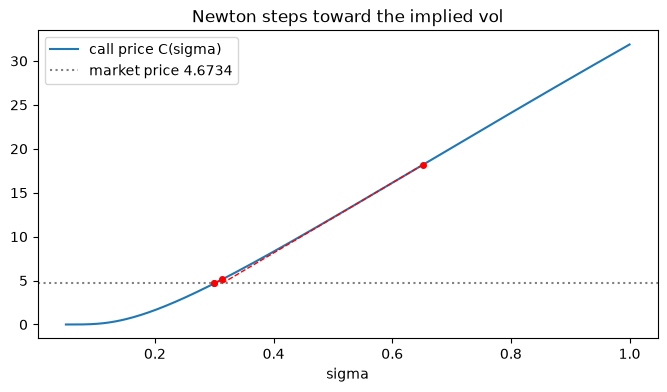

step 0: sigma = 0.6517119985
step 1: sigma = 0.3130725465
step 2: sigma = 0.3001236616
step 3: sigma = 0.3000000122
step 4: sigma = 0.3000000000
ope: sigma = 0.3000000000 after 5 iterations


In [11]:
S0, K0, T0, r0, true_sigma = 100.0, 130.0, 1.0, 0.05, 0.30
target = float(call_price(S0, K0, T0, r0, true_sigma))
forward0 = S0 * math.exp(r0 * T0)

path = [math.sqrt(2 * abs(math.log(forward0 / K0)) / T0)]
for _ in range(4):
    s = path[-1]
    step = (float(call_price(S0, K0, T0, r0, s)) - target) / float(
        greeks("call", S0, K0, T0, r0, s).vega
    )
    path.append(s - step)

grid = np.linspace(0.05, 1.0, 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, call_price(S0, K0, T0, r0, grid), label="call price C(sigma)")
ax.axhline(target, color="gray", linestyle=":", label=f"market price {target:.4f}")
for s, s_next in itertools.pairwise(path):
    c = float(call_price(S0, K0, T0, r0, s))
    ax.plot([s, s_next], [c, target], color="red", linestyle="--", linewidth=1)
    ax.plot(s, c, "o", color="red", markersize=4)
ax.set_xlabel("sigma")
ax.set_title("Newton steps toward the implied vol")
ax.legend()
plt.show()

for i, s in enumerate(path):
    print(f"step {i}: sigma = {s:.10f}")
res = implied_vol_result("call", target, S0, K0, T0, r0)
print(f"ope: sigma = {res.sigma:.10f} after {res.iterations} iterations")

## 11. Newton vs. bisection

Bisection halves an interval that holds the root at every step: slow but impossible to break.
Newton is much faster near the money, but where vega is tiny (deep in or out of the money,
short-dated) one step can jump to an absurd $\sigma$. `ope` keeps a bracket around the root and
turns any Newton step that would leave it into a bisection step.

The table compares, at the same tolerance, `ope`'s solver, pure bisection on $[0, 1]$, and pure
Newton started at $\sigma = 0.2$, for options all priced at a true vol of 30%.

In [12]:
TOL = 1e-12


def pure_bisection(option, target, S, K, T, r):
    lo, hi = 0.0, 1.0
    for i in range(1, 200):
        mid = 0.5 * (lo + hi)
        diff = float(price(option, S, K, T, r, mid)) - target
        if abs(diff) <= TOL * max(1.0, target):
            return i
        lo, hi = (lo, mid) if diff > 0 else (mid, hi)
    return -1


def pure_newton(option, target, S, K, T, r):
    sigma = 0.2
    for i in range(1, 51):
        model = float(price(option, S, K, T, r, sigma))
        vega = float(greeks(option, S, K, T, r, sigma).vega)
        if abs(model - target) <= TOL * max(1.0, target):
            return f"converged in {i}"
        if vega == 0.0:
            return f"fails at step {i}: vega is 0"
        sigma -= (model - target) / vega
        if sigma <= 0 or not math.isfinite(sigma):
            return f"fails at step {i}: sigma = {sigma:.3g}"
    return "no convergence in 50 steps"


cases = [
    ("ATM 1y call", "call", 100.0, 1.0),
    ("OTM 1y call K=130", "call", 130.0, 1.0),
    ("ITM 1y call K=70", "call", 70.0, 1.0),
    ("deep OTM 1w call K=125", "call", 125.0, 7 / 365),
    ("deep ITM 1w put K=125", "put", 125.0, 7 / 365),
    ("far OTM 1m put K=60", "put", 60.0, 1 / 12),
]
print(f"{'case':24s} {'price':>11s} {'ope (newton+bisect)':>20s} {'bisection':>10s}  pure newton")
for name, option, K1, T1 in cases:
    target1 = float(price(option, 100.0, K1, T1, 0.05, 0.30))
    res = implied_vol_result(option, target1, 100.0, K1, T1, 0.05)
    split = f"{res.iterations} ({res.newton_steps}+{res.bisection_steps})"
    bis = pure_bisection(option, target1, 100.0, K1, T1, 0.05)
    newt = pure_newton(option, target1, 100.0, K1, T1, 0.05)
    print(f"{name:24s} {target1:11.4g} {split:>20s} {bis:>10d}  {newt}")

case                           price  ope (newton+bisect)  bisection  pure newton
ATM 1y call                    14.23              3 (2+0)         40  converged in 4
OTM 1y call K=130              4.673              5 (4+0)         42  converged in 5
ITM 1y call K=70                34.4              6 (5+0)         38  converged in 7
deep OTM 1w call K=125     3.628e-08            14 (13+0)         20  fails at step 2: vega is 0
deep ITM 1w put K=125          24.88            14 (13+0)         16  fails at step 2: vega is 0


far OTM 1m put K=60        1.463e-09            16 (15+0)         16  fails at step 2: vega is 0

Why pure Newton dies on the deep OTM call: at $\sigma = 0.2$ its vega is around $10^{-14}$, so
the first step divides a small price gap by an even smaller number.

In [13]:
S1, K1, T1 = 100.0, 125.0, 7 / 365
target1 = float(call_price(S1, K1, T1, 0.05, 0.30))
vega0 = float(greeks("call", S1, K1, T1, 0.05, 0.2).vega)
gap0 = float(call_price(S1, K1, T1, 0.05, 0.2)) - target1
print(f"vega at sigma = 0.2: {vega0:.2e}")
print(f"price gap:          {gap0:.2e}")
print(f"first newton step:  sigma = 0.2 - gap/vega = {0.2 - gap0 / vega0:.3g}")
print(f"vega there:         {float(greeks('call', S1, K1, T1, 0.05, 0.2 - gap0 / vega0).vega):.1e}")

vega at sigma = 0.2: 6.56e-14
price gap:          -3.63e-08
first newton step:  sigma = 0.2 - gap/vega = 5.53e+05
vega there:         0.0e+00
